Dataset shape: (5172, 3002)

First five rows:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Class distribut

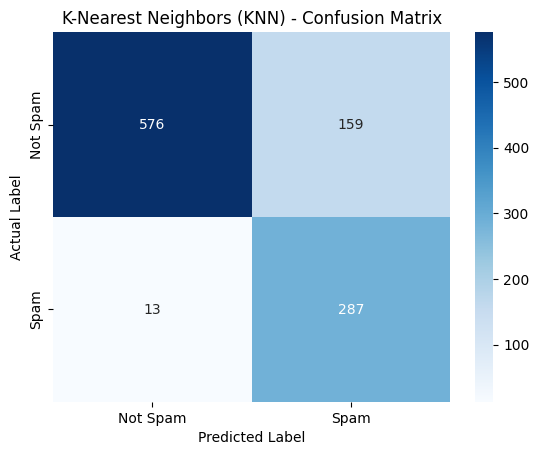


Support Vector Machine (SVM)
Accuracy : 0.9507
Precision: 0.9136
Recall   : 0.9167
F1 Score : 0.9151

Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      0.96      0.97       735
        Spam       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



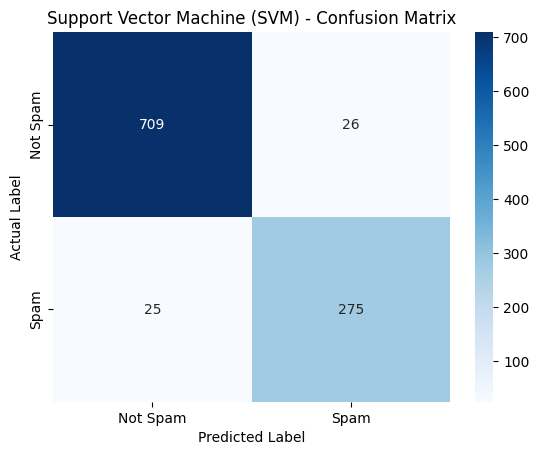


Performance Comparison:
Model  Accuracy  Precision  Recall  F1 Score
  KNN    0.8338     0.6435  0.9567    0.7694
  SVM    0.9507     0.9136  0.9167    0.9151


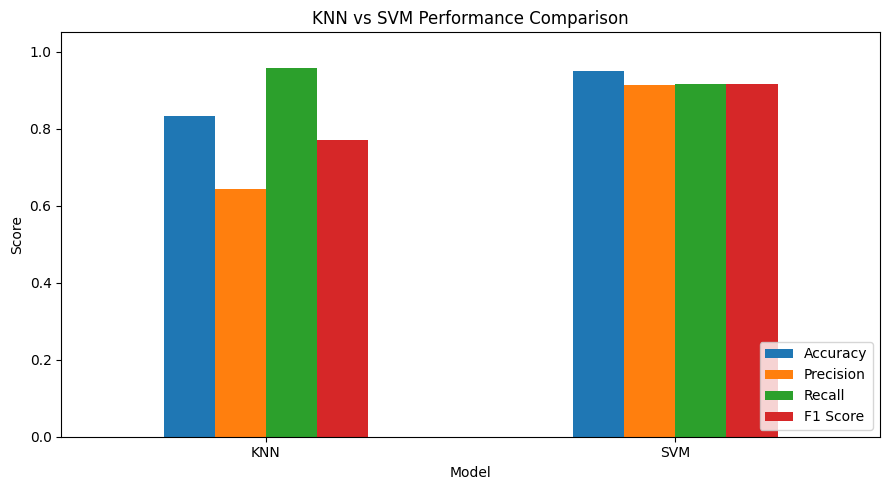


Better model based on F1 Score: SVM


In [3]:
# Email Spam Classification using KNN and SVM

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Step 1: Load the dataset
df = pd.read_csv("emails.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

# Step 2: Check and clean the dataset
df = df.drop_duplicates()
df = df.dropna()

# Remove email ID column if present
if "Email No." in df.columns:
    df = df.drop(columns=["Email No."])

# Step 3: Separate features and target
X = df.drop(columns=["Prediction"])
y = df["Prediction"]

# Convert target into binary classes:
# 0 = Not Spam, 1 = Spam
y = (y > 0).astype(int)

print("\nClass distribution:")
print(y.value_counts())

# Step 4: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 5: Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Create classification models
knn = KNeighborsClassifier(n_neighbors=5)

svm = SVC(kernel="linear", random_state=42)

# Step 7: Train the models
knn.fit(X_train_scaled, y_train)
svm.fit(X_train_scaled, y_train)

# Step 8: Make predictions
knn_pred = knn.predict(X_test_scaled)
svm_pred = svm.predict(X_test_scaled)

# Step 9: Evaluate model performance
def evaluate_model(name, y_true, y_pred):
    print(f"\n{'=' * 40}")
    print(name)
    print("=" * 40)

    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(
        y_true, y_pred, zero_division=0
    ), 4))
    print("Recall   :", round(recall_score(
        y_true, y_pred, zero_division=0
    ), 4))
    print("F1 Score :", round(f1_score(
        y_true, y_pred, zero_division=0
    ), 4))

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=[0, 1],
        target_names=["Not Spam", "Spam"],
        zero_division=0
    ))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Spam", "Spam"],
        yticklabels=["Not Spam", "Spam"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.show()


# Step 10: Display results for both models
evaluate_model("K-Nearest Neighbors (KNN)", y_test, knn_pred)
evaluate_model("Support Vector Machine (SVM)", y_test, svm_pred)

# Step 11: Compare model performance
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],
    "Precision": [
        precision_score(y_test, knn_pred, zero_division=0),
        precision_score(y_test, svm_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, knn_pred, zero_division=0),
        recall_score(y_test, svm_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, knn_pred, zero_division=0),
        f1_score(y_test, svm_pred, zero_division=0)
    ]
})

print("\nPerformance Comparison:")
print(results.round(4).to_string(index=False))

# Step 12: Plot accuracy comparison
results.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1 Score"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("KNN vs SVM Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Step 13: Identify the model with the higher F1 score
best_model = results.loc[results["F1 Score"].idxmax(), "Model"]
print("\nBetter model based on F1 Score:", best_model)